# 사출했는데 압력이 안 떨어짐 — 무엇을 못 잡나 (P1, 9/10~10/06)

**규칙 후보**: "사출(S1 `Shot_Injection_HD1_P1`)이 있었는데 압력이 안 떨어지면 이상".
- S1 이벤트 하락 = (S1 시작 직전 2틱 평균 − [S1 ON ~ 끝+2틱] 중 최저) / 직전 2틱 평균. BuildUp OFF 틱은 잘라냄.
- "안 떨어짐" = 하락 < 5% (또는 < 3%).

- 데이터: 9/10~10/06 매일 07:00~23:50, P1 (`code_ongoing/inj_dip_pull_daily.py` → `parkkt/cache/inj_dip_daily/`). 일요일·추석연휴(9/24~27)는 비가동이라 빠져 운전일 20일.
- 틱 ≈ 0.52초, 한 사이클 ≈ 15틱. 로깅 주기·기록률은 기간 내내 같다 (연휴 전후 비교가 측정 방식 차이가 아님).
- 판정 대상 틱: 기준 2틱 + 현재 틱이 모두 BuildUp=1, 같은 사이클, tick≥1 (펌프 꺼짐/증압 첫 틱 제외).
- 계산은 `code_ongoing/inj_dip_daily_lib.py`, 그림은 `code_ongoing/inj_dip_daily_viz.py`.

In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
from inj_dip_daily_viz import *
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
r = process_all()          # 처음/데이터 갱신 후에는 process_all(force=True)
D, AL, E = r['days'], r['alarms'], r['events']
print(f'운전일 {len(D)}일 ({D.index.min():%m/%d}~{D.index.max():%m/%d}), 사이클 {D.cycles.sum():,}개, S1 이벤트 {len(E):,}개')

운전일 20일 (09/10~10/06), 사이클 56,389개, S1 이벤트 57,396개


## 1. 핵심: 사출 하락 폭은 레시피(SV)에 따라 다르고, 추석 연휴를 기점으로 크게 줄었다

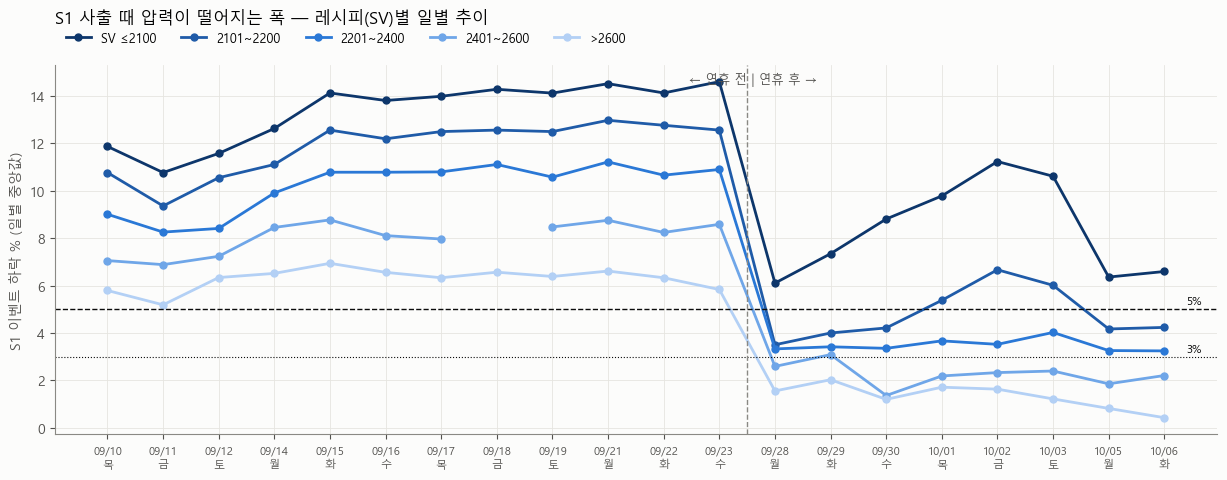

In [2]:
fig_s1_trend(E); plt.show()

- **연휴 전 (9/10~9/23)**: 모든 레시피에서 S1 하락 중앙값 6~15%. 날마다 거의 일정.
- **연휴 후 (9/28~)**: 첫날부터 계단식으로 1/2~1/4 로 줄었다. SV ≤2100 만 5% 위에 있고, 나머지는 1~4%.
- 같은 레시피의 **기준 압력(사출 전 압력)은 거의 그대로**다 (SV 2010: 92 → 90.5). 압력 수준이 아니라 **사출 순간 압력이 빠지는 폭만** 줄었다.
- 로깅 주기(0.523초)·S1 신호 길이(2틱)·최저점 위치(S1 시작 1틱 뒤)도 기간 내내 같다 → 데이터 수집 방식 변화가 아니라 **설비 거동 변화**로 보인다.

In [3]:
t = E.assign(era=era(E.day)).query('sv in [2010, 2150, 2350, 2680, 2800]').pivot_table(
    index='sv', columns='era', values=['base', 'drop_abs', 'drop_pct'], aggfunc='median').round(1)
t.columns = [f'{a}·{b}' for a, b in t.columns]
t.rename(columns=lambda c: c.replace('base', '기준압력').replace('drop_abs', '하락(눈금)').replace('drop_pct', '하락%'))

,기준압력·연휴 전,기준압력·연휴 후,하락(눈금)·연휴 전,하락(눈금)·연휴 후,하락%·연휴 전,하락%·연휴 후
sv,,,,,,
2010.0,92.0,90.5,12.5,7.5,13.5,8.6
2150.0,98.0,94.5,11.5,4.5,11.9,4.9
2350.0,107.0,103.0,11.5,4.0,10.6,3.6
2680.0,123.0,122.5,8.0,2.5,6.4,2.0
2800.0,132.5,128.0,7.5,0.0,5.6,0.0


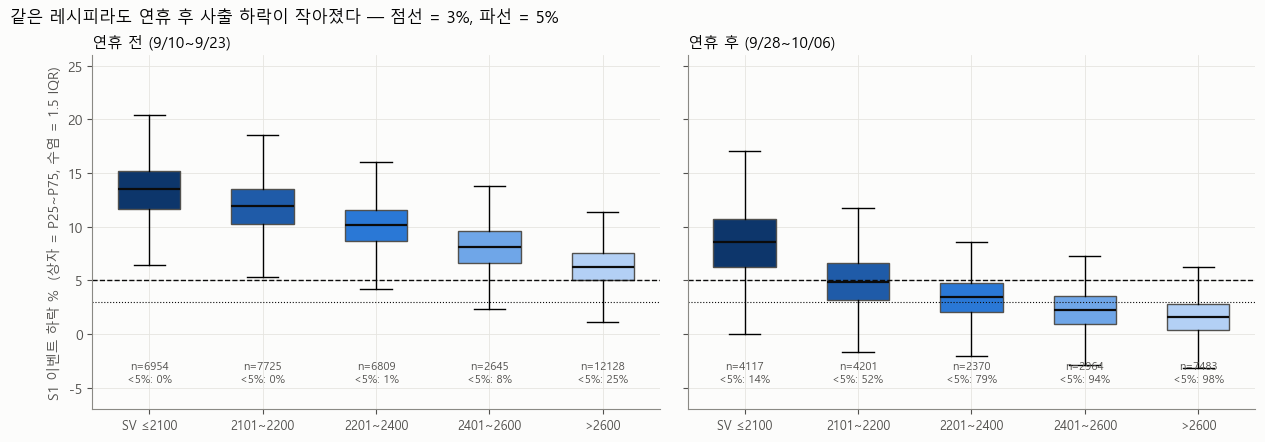

In [4]:
fig_s1_dist(E); plt.show()

## 2. 이 규칙을 이벤트 단위 경보로 쓰면 하루에 몇 번 울리나

In [5]:
s1_rule_table(E)

S1이벤트    하루평균  하락중앙  하락P10  <3% 비율  <5% 비율  <3% 하루 알람
era  svb                                                             
연휴 전 SV ≤2100    6954   579.5  13.5   10.1     0.0     0.2        0.2
     2101~2200   7725   643.8  11.9    8.6     0.0     0.3        0.0
     2201~2400   6809   567.4  10.2    7.2     0.1     1.4        0.6
     2401~2600   2645   240.5   8.1    5.3     1.4     8.1        3.5
     >2600      12128  1010.7   6.3    3.8     4.7    24.6       47.7
연휴 후 SV ≤2100    4117   514.6   8.6    4.3     4.5    14.2       23.0
     2101~2200   4201   525.1   4.9    1.7    22.7    52.2      119.0
     2201~2400   2370   296.2   3.4    1.0    41.6    79.2      123.2
     2401~2600   2964   370.5   2.2    0.0    65.2    93.8      241.5
     >2600       7483   935.4   1.6   -0.8    80.1    98.0      749.5

- **연휴 전에는 쓸 수 있었다**: SV ≤2400 에서 하락 <3% 인 S1 이 0~0.1% — 하루 1번도 안 울린다. 즉 "사출하면 압력이 반드시 떨어진다"가 성립했다. 고유량(>2600)만 <3% 가 4.7% (하루 약 48번).
- **연휴 후에는 못 쓴다**: <3% 가 SV ≤2100 에서 4.5%, 2101~2200 에서 23%, >2600 에서 80% — 하루 수백 번.
- 즉 지금 "쓸 수 없다"는 건 규칙 자체가 틀렸다기보다, **연휴 전의 정상 상태와 지금 상태가 다르기 때문**이다. 연휴 전을 기준(정상)으로 보면, 연휴 후 전체가 이 규칙에 걸리는 "이상"이다.

## 3. 무엇을 못 잡나 (= 정상인데도 안 떨어지는 경우)

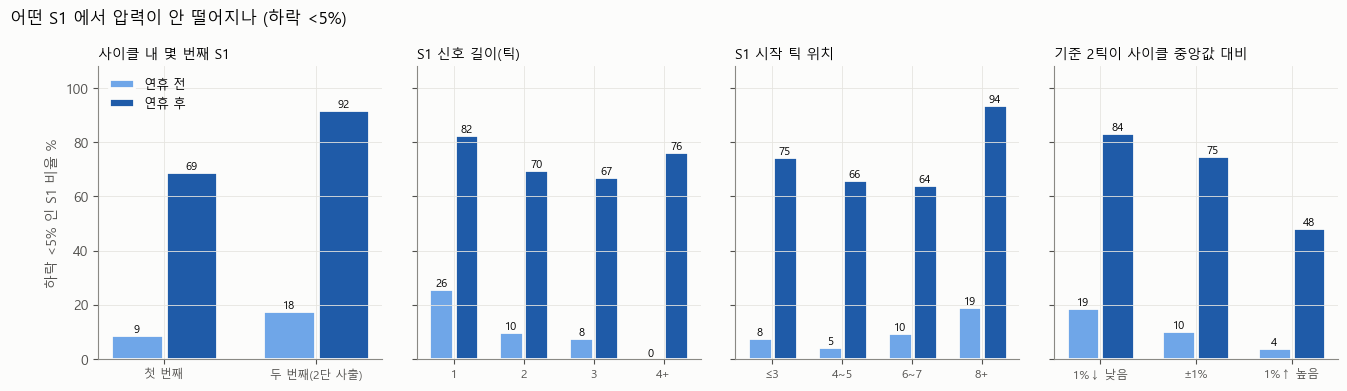

In [6]:
fig_s1_factors(E, thr=5); plt.show()

연휴 전 기준 (연휴 후는 전부 높아서 조건별 차이가 묻힌다):
1. **고유량 레시피 (SV >2600)**: 원래 하락이 작다 (중앙 6%, 25% 가 <5%). 기준 압력이 높아(120~135) 같은 눈금 하락이 %로 작고, 하락 눈금 자체도 작다. → 이 레시피에서는 "안 떨어짐" 판정을 쓰면 안 된다.
2. **사이클의 두 번째 S1 (2단 사출 레시피)**: <5% 가 18% (첫 번째는 9%). SV 하향 직후라 기준 압력 자체가 내려가는 중이다.
3. **S1 신호가 1틱뿐인 짧은 사출**: <5% 가 26% — 로깅(0.52초) 사이에 하락이 회복돼 버려 최저점이 안 찍혔을 가능성.
4. **S1 이 늦게(tick 8+) 시작**: 19%. 대부분 위 2번(두 번째 사출)과 같은 사이클.
5. **기준 2틱이 이미 낮을 때** (사이클 중앙값보다 1% 이상 낮음): 19% — 앞에서 이미 압력이 내려가 있어 "직전 대비" 하락이 작게 잡힌다 (기준값 정의의 한계).

반대로 **연휴 전, SV ≤2400, 첫 번째 S1, 신호 2틱 이상** 이면 <5% 가 거의 없다 → 이벤트 단위 규칙을 쓴다면 이 조건으로 좁혀서 써야 한다.

## 4. 같은 레시피, 연휴 전 vs 후 실제 모습 (SV 2150)

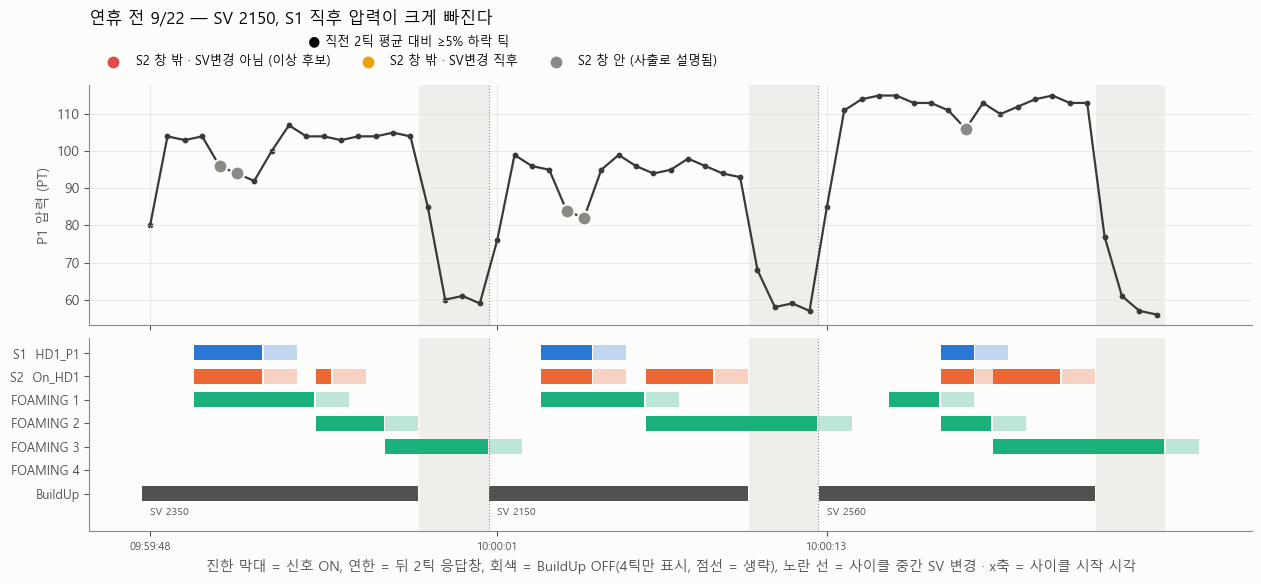

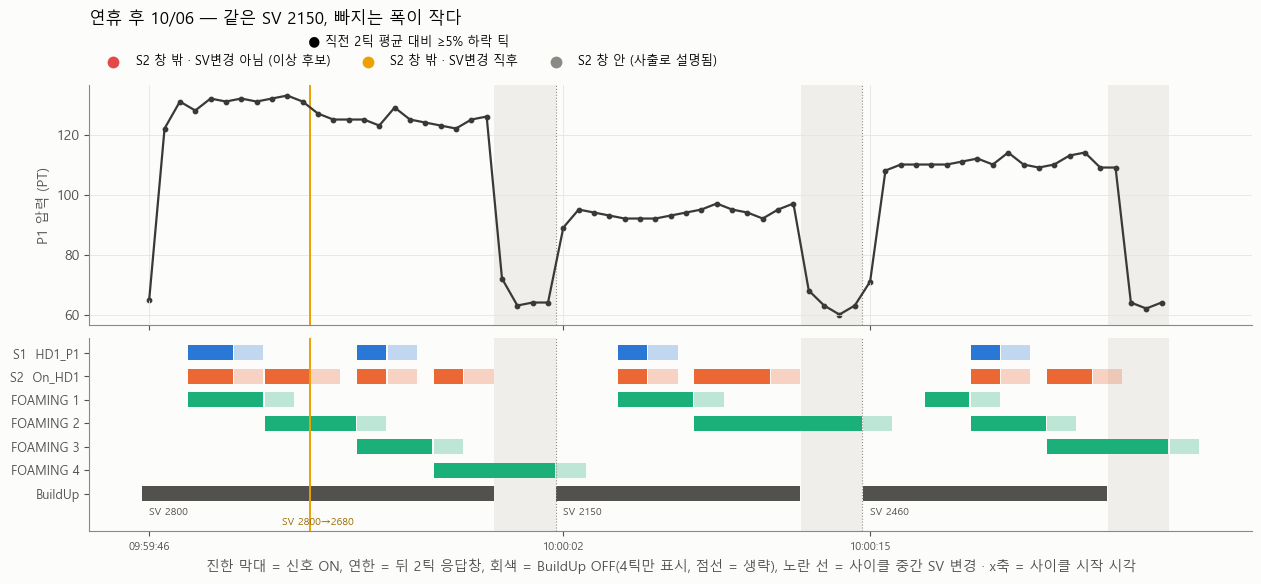

In [7]:
def pick(day, sv, hour=10):
    e = E[(E.day == day) & (E.sv == sv) & (E.nth_s1 == 1)]
    return e.iloc[np.argmin(np.abs(e.Time.dt.hour * 60 + e.Time.dt.minute - hour * 60))].Time
fig_around('2026-09-22', pick('2026-09-22', 2150), before=1, after=1, thr=5, title='연휴 전 9/22 — SV 2150, S1 직후 압력이 크게 빠진다'); plt.show()
fig_around('2026-10-06', pick('2026-10-06', 2150), before=1, after=1, thr=5, title='연휴 후 10/06 — 같은 SV 2150, 빠지는 폭이 작다'); plt.show()

(위 그림의 점 색 범례는 노트북 A 와 같은 "창 밖 하락" 기준이라 여기선 참고만 — 볼 것은 S1(파랑) 직후 압력선의 꺼짐 폭.)

## 5. 정리

| | 결론 |
|---|---|
| 이벤트 단위 "사출했는데 안 떨어짐" 경보 | **지금은 못 쓴다.** 연휴 후 하락 폭이 1/2~1/4 로 줄어 SV 2200 이상에선 S1 의 23~80% 가 <3%. 연휴 전에는 SV ≤2400 에서 0~0.1% 로 쓸 수 있었다 |
| 원래부터 못 잡는 것 | 고유량(SV >2600), 2단 사출의 두 번째 S1, 1틱짜리 짧은 S1, 기준 2틱이 이미 낮은 경우 |
| 쓸 수 있는 형태 | **레시피별 일별 하락 중앙값 추이** (1절 그림). 이벤트 하나하나는 흔들려도 하루 수백 개의 중앙값은 안정적이라, 이번 연휴 전후 변화처럼 **계단식 변화를 확실하게 잡는다** |

**확인이 필요한 것**: 연휴(9/24~27) 동안 HD1 / P1 계통에 무슨 작업이 있었는지 (어큐뮬레이터 충전·교체, 사출 밸브·노즐 정비, 압력센서 교체/교정, PLC 사출 타이밍 변경 등).
- 정비 결과라면 → 연휴 후가 새 정상. 규칙 기준을 연휴 후 데이터로 다시 잡아야 한다 (이 경우 SV ≤2100 만 이벤트 경보 가능).
- 아무 작업도 없었다면 → 연휴 전후로 설비 상태가 바뀐 것이라 그 자체가 점검 대상이다. 참고로 같은 HD1 짝인 I1 의 압력 저하 이상(9/29)도 연휴 직후다.